In [1]:
#import bioalpha
import scanpy as sc
import pandas as pd
import numpy as np
import os
import re
import anndata as ad
import pandas as pd

In [2]:
import warnings
warnings.simplefilter(action='ignore', category=FutureWarning)
exec(open('/scratch/wyang114/bin/utils/_figure_options.py').read())
plt.rcParams['pdf.fonttype'] = 42
plt.rcParams['font.family'] = 'sans-serif'
np.random.seed(2023)

/packages/apps/mamba/1.5.1/lib/python3.11/site-packages/scanpy/plotting/_tools/scatterplots.py:394: UserWarning: No data for colormapping provided via 'c'. Parameters 'cmap' will be ignored
  cax = scatter(


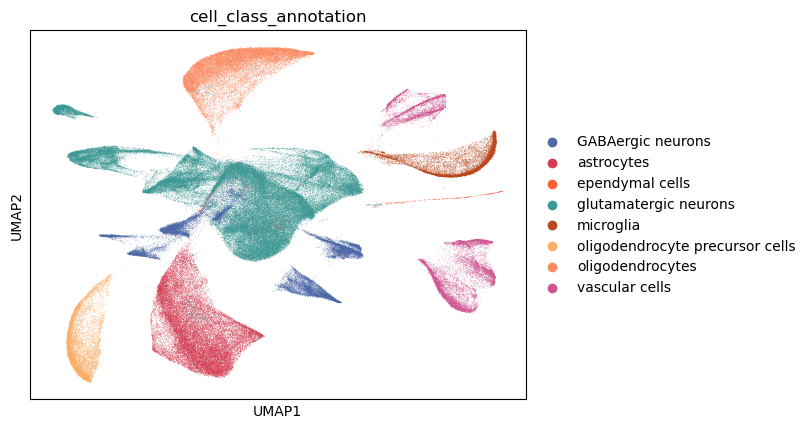

In [ ]:
######REGION UMAPS
#Remove doublets from finalized files and replot umap
data_dir = '/scratch/nsnyderm/u01/intermediate_files/finalized_class_annotation/'
region = 'ec'
adata = sc.read(data_dir+region+'_processed_w_siletti.h5ad')
adata = adata.raw.to_adata()
adata.raw = adata
select_index = adata.obs.index[np.where(~adata.obs['cell_class_annotation'].isin(['doublet']))]
select_genes = adata.var.index[np.where(~adata.var['chr'].isin(['X','Y']))] # genes mapping to X/Y chr is removed
adata = adata[select_index,select_genes].copy()

bioalpha.sc.pp.normalize_total(adata, target_sum=1e4)
bioalpha.sc.pp.log1p(adata)
bioalpha.sc.pp.highly_variable_genes(adata, n_top_genes=10000)
adata = adata[:, adata.var.highly_variable]
adata.layers['normalized_unscaled'] = adata.X
sc.pp.regress_out(adata, keys='n_umi',n_jobs =20)   #regress_out step: ec
bioalpha.sc.pp.scale(adata, max_value=10)
bioalpha.sc.tl.pca(adata, n_comps=50)
bioalpha.sc.pp.neighbors(adata, n_neighbors=30, n_pcs=30)
bioalpha.sc.tl.umap(adata,min_dist=0.5,spread=1.0, n_components=2)  #0.25-0.5
sc.pl.umap(adata,color='cell_class_annotation',save=f'_{region}.pdf')
adata.write_h5ad(data_dir+region+'_processed_w_siletti_rmdoublet.h5ad')

/tmp/ipykernel_2753314/897873635.py:7: DtypeWarning: Columns (15,22) have mixed types. Specify dtype option on import or set low_memory=False.
  df_all = pd.read_csv('/scratch/wyang114/outputs/celltype_obs/all_obs.csv')


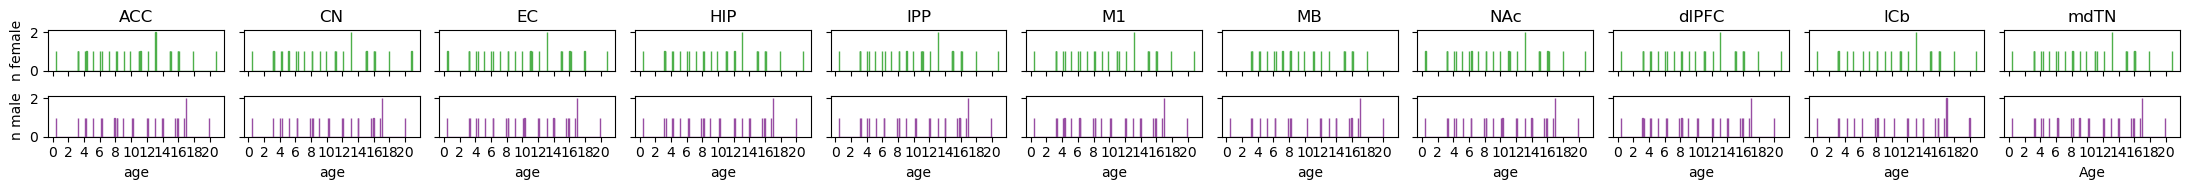

In [21]:
#####ALL REGION ANIMAL COUNTS
import pandas as pd
import matplotlib.pyplot as plt
import collections
import seaborn as sns

df_all = pd.read_csv('/scratch/wyang114/outputs/celltype_obs/all_obs.csv')

# #For histogram with bin>=0.05
df_sample = df_all.groupby(['region','sex','age','animal_id']).size().to_frame('count').reset_index()
# g = sns.displot(
#     data=df_sample, x="age", hue="sex", row="sex", col="region",kind="hist",
#     kde=False, height=2, aspect=2,palette=sex_colors
# )
# plt.savefig(f'/scratch/wyang114/figures/1_paper_figures/2_figS1/animal_age_byregion_bin0.01.pdf',bbox_inches='tight',format='pdf')

regions = df_sample["region"].unique()

fig, axes = plt.subplots(nrows=2, ncols=len(regions), figsize=(2 * len(regions),2), sharex=True, sharey=True)

# Ensure axes is always iterable (even for 1 region)
if len(regions) == 1:
    axes = [axes]

# Loop through each region and plot
for i in range(len(regions)):
    # Plot Female
    region=regions[i]
    sns.histplot(data=df_sample[(df_sample['sex'] == 'F') & (df_sample['region'] == region)], 
                 x='age', binwidth=0.01, ax=axes[0,i], edgecolor=sex_colors[0], linewidth=1, 
                 label="Female", color=sex_colors[0])
    
    # Plot Male
    sns.histplot(data=df_sample[(df_sample['sex'] == 'M') & (df_sample['region'] == region)], 
                 x='age', binwidth=0.01, ax=axes[1,i], edgecolor=sex_colors[1], 
                 linewidth=1, label="Male", color=sex_colors[1])
    
    # Formatting
    axes[0,i].set_title(region)  # Label each region
    axes[0,i].set_ylabel('n female')  # Label each region
    axes[1,i].set_ylabel('n male')  # Label each region
    axes[0,i].set_yticks(np.array([0,2]))  # Adjust y-axis ticks
    axes[1,i].set_yticks(np.array([0,2]))  # Adjust y-axis ticks
    axes[1,i].set_xticks(np.arange(0, 22, 2))  # Set consistent age bins

# Set common x-axis label
plt.xlabel("Age")
plt.tight_layout()  # Adjust layout


plt.savefig(f'/scratch/wyang114/figures/1_paper_figures/2_figS1/animal_age_byregion_bin0.01.pdf',bbox_inches='tight',format='pdf')

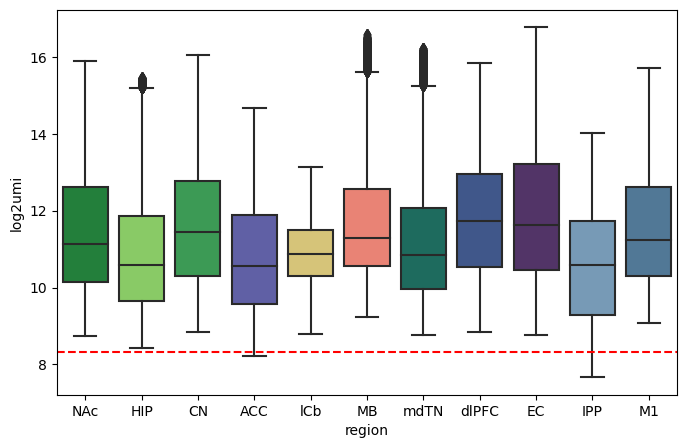

In [12]:
#df_all = pd.read_csv('/scratch/wyang114/outputs/celltype_obs/all_obs.csv')
my_map = color_map.loc[color_map['class'].isin(df_all['region']),].set_index('class')
my_map= my_map.rename_axis('region')
df_all['color'] = df_all['region'].map(my_map.to_dict()['color'])
fig,ax=plt.subplots(1,1,figsize=[8,5])
sns.boxplot(x='region',y='log2umi', data=df_all, palette = my_map.to_dict()['color'],ax=ax)
plt.axhline(y=np.log2(320), color='r', linestyle='--')
plt.savefig(f'/scratch/wyang114/figures/1_paper_figures/2_figS1/region_umi.pdf',bbox_inches='tight',format='pdf')

<Figure size 1000x600 with 0 Axes>

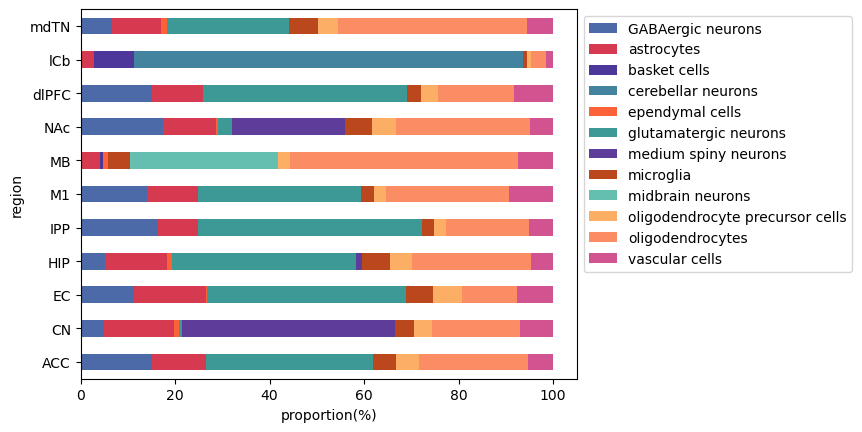

In [22]:
df_bar = df_all.groupby(['region'])['cell_class_annotation'].value_counts(normalize=True).reset_index()
my_map = color_map.loc[color_map['class'].isin(df_bar['cell_class_annotation']),].set_index('class')
my_map= my_map.rename_axis('cell_class_annotation')
df_bar = df_all.groupby(['region'])['cell_class_annotation'].value_counts(normalize=True).unstack()
df_bar = df_bar*100
plt.figure(figsize=(10,6))
df_bar.plot.barh( stacked=True, color = my_map.to_dict()['color'])
plt.xlabel('proportion(%)')
plt.legend(bbox_to_anchor=(1, 1),loc = 'upper left')
plt.savefig(f'/scratch/wyang114/figures/1_paper_figures/2_figS1/region_ct_distribution.pdf',
            bbox_inches='tight',format='pdf')

## Infant analysis

(55, 29060)


/home/wyang114/.conda/envs/TACCO_env/lib/python3.11/site-packages/scanpy/preprocessing/_simple.py:843: UserWarning: Received a view of an AnnData. Making a copy.
  view_to_actual(adata)


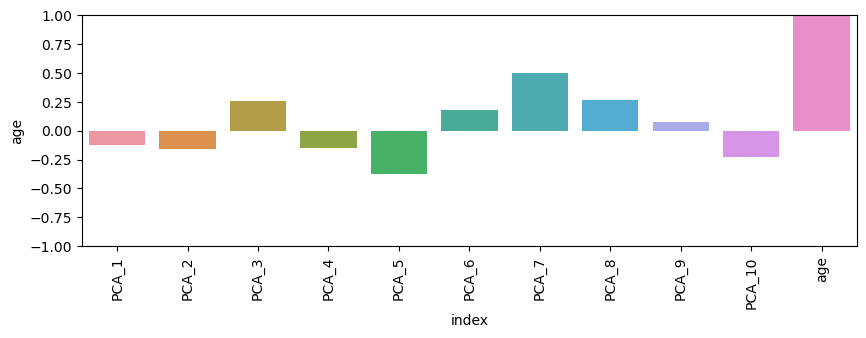

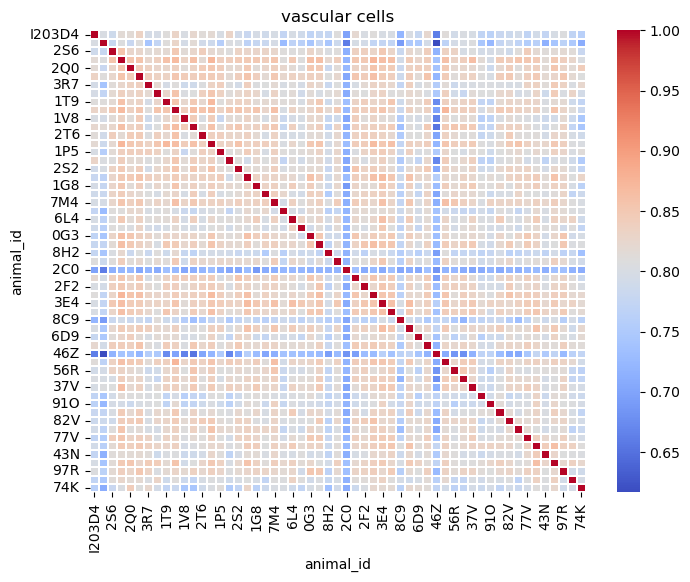

In [40]:
ct = 'vascular cells'
npcs=10
meta = pd.read_csv(f'/scratch/wyang114/outputs/pseudobulk/cell_type/{ct}_meta.csv',header=0,index_col=0)
mat = pd.read_csv(f'/scratch/wyang114/outputs/pseudobulk/cell_type/{ct}_mat.csv',header=0,index_col=0)  
meta.index = meta['sample_id']
mat = mat.loc[meta.index,]
#pseudobulk by animals
one_hot_sample = pd.get_dummies(meta['animal_id']).values.astype(int)
pb_sample_mat = mat.T.dot(one_hot_sample).T
print(pb_sample_mat.shape)
pb_meta = pd.DataFrame(meta.groupby(['animal_id','age','sex']).size().rename('NCells')).reset_index()
pb_meta = pb_meta[pb_meta['NCells']>0]
pb_sample_mat.index = pb_meta['animal_id']
pb_meta.index = pb_meta['animal_id']
pb_meta = pb_meta.iloc[:,1:3]
# #using all genes to perform correlation
# animal_order = pb_meta.sort_values('age').index
# correlation_matrix = pb_sample_mat.T.corr(method='spearman')
# import seaborn as sns
# import matplotlib.pyplot as plt
# # Plot the heatmap
# plt.figure(figsize=(8, 6))  # Set the figure size
# sns.heatmap(correlation_matrix.loc[animal_order,animal_order], annot=False, cmap='coolwarm', linewidths=0.1)

pb_adata = ad.AnnData(pb_sample_mat,obs = pb_meta)
sc.pp.highly_variable_genes(pb_adata, n_top_genes=10000) #hvg
pb_adata = pb_adata[:, pb_adata.var.highly_variable]
sc.pp.scale(pb_adata, max_value=10)
sc.tl.pca(pb_adata, n_comps=npcs)
df_cor = pd.DataFrame(pb_adata.obsm['X_pca'],columns=['PCA_'+str(i+1) for i in range(npcs)])
df_cor.index = df_cor.index.astype('str')
df_cor['age']=pb_adata.obs['age'].values
correlations = pd.DataFrame(df_cor.corr()['age']).reset_index()
fig,ax=plt.subplots(1,1,figsize=(10,3))
sns.barplot(x='index', y='age', data=correlations.iloc[:50,:],ax=ax)
plt.xticks(rotation=90);
plt.ylim(-1,1)
plt.savefig(f'/scratch/wyang114/figures/1_paper_figures/2_figS1/{ct}_sample_gene_cor_pcs.pdf',
            bbox_inches='tight',format='pdf')

pc=abs(correlations.iloc[:npcs,1]).idxmax()
pc_loadings = pb_adata.varm['PCs'][:, pc]
loading_df = pd.DataFrame({
    'Gene': pb_adata.var_names,
    'Loading': pc_loadings
})
top_genes = loading_df.reindex(loading_df['Loading'].abs().sort_values(ascending=False).index).head(500)
select_mat = pb_sample_mat.loc[:,top_genes['Gene']]
animal_order = pb_meta.sort_values('age').index
correlation_matrix = select_mat.T.corr(method='spearman')
plt.figure(figsize=(8, 6))  # Set the figure size
sns.heatmap(correlation_matrix.loc[animal_order,animal_order], annot=False, cmap='coolwarm',linewidths=0.1,)
plt.title(ct)
plt.savefig(f'/scratch/wyang114/figures/1_paper_figures/2_figS1/{ct}_sample_gene_cor_pc{pc+1}.pdf',
            bbox_inches='tight',format='pdf')